# Multi-Agent Financial Analysis System

**AAI-520 Final Team Project — Brandon Wirgau, Christina, and Isaac**

This notebook is the canonical, executable report for an agentic investment-research system. It accepts a stock ticker and user research question, uses LangGraph to route a bounded run to market, financial, news, or comprehensive specialists, evaluates and revises the complete report, and stores reusable lessons for later runs.

Repository: [AAI-520 Final Project](https://github.com/bwirgau-usd/AAI-520-final-project-multi-agent-financial-analysis)

> Research support only. The output is not personalized investment advice and does not guarantee future performance.


## 1. Project objectives and implemented capabilities

The project demonstrates four autonomous agent functions:

1. **Plan** research objectives, questions, and tool selection using prior-run memory as context.
2. **Use tools** to retrieve Yahoo Finance market/fundamental data, SEC EDGAR facts and filings, and multi-source company news.
3. **Reflect and evaluate** data quality, report grounding, and specialist-analysis completeness.
4. **Learn across runs** by persisting bounded, timestamped research lessons.

It also implements all three required workflow patterns:

- **Prompt chaining:** ingest → preprocess → classify → extract → summarize.
- **Routing:** the user request selects market-only, financial-only, news-only, or comprehensive research; news articles also route to earnings, market, and general-news specialists.
- **Evaluator–optimizer:** article analysis uses a four-part rubric, while the complete report is scored for completeness, grounding, reasoning, consistency, sources, and clarity and revised through a bounded LangGraph loop.

The refactored modules preserve the original notebook's planning, tool execution, validation, reflection, reporting, memory, SEC EDGAR retrieval, 10-year price graph, revenue and operating-expense analysis, multi-source news analysis, specialist routing, and iterative optimization. The updated Google News RSS fallback and retry-aware HTTP behavior are included as well.


## 2. Implemented system architecture

The research workflow keeps provider adapters, provider-independent tools, agents, workflows, memory, and presentation concerns separate. This makes each stage inspectable and independently testable.

```mermaid
flowchart LR
    U[User ticker and research question] --> P[Planner]
    L[Research memory] --> P
    P --> RQ{Request route}
    RQ -->|Market| MA[Market specialist]
    RQ -->|Financial| FA[Financial specialist]
    RQ -->|News| C[News prompt chain]
    RQ -->|Comprehensive| MA
    RQ -->|Comprehensive| FA
    RQ -->|Comprehensive| C
    Y[Yahoo Finance] --> MA
    Y --> FA
    S[SEC EDGAR] --> FA
    Y --> C
    N[NewsAPI] --> C
    G[Google News RSS fallback] --> C
    C --> R[Specialist router]
    R --> E[Earnings specialist]
    R --> M[Market specialist]
    R --> W[News specialist]
    E --> V[Evaluator / optimizer]
    M --> V
    W --> V
    MA --> Z[Synthesizer]
    FA --> Z
    V --> Z
    Z --> Q{Six-part report evaluator}
    Q -->|Below threshold| O[Report optimizer]
    O --> Q
    Q -->|Pass or revision limit| F[Final report and visuals]
    F --> L
```


## 3. Environment setup

Create and activate a virtual environment, install `requirements.txt`, start Ollama, and copy `.env.example` to `.env`. At minimum:

- `OLLAMA_MODEL=llama3.2` and a running `ollama serve` process;
- `SEC_USER_AGENT` containing an application name and monitored contact email;
- optional `NEWS_API_KEY` (Yahoo remains primary and Google RSS is a fallback);
- optional `DEFAULT_TICKER`, `RESEARCH_REQUEST`, `MAX_NEWS_ARTICLES`, `EVALUATION_SCORE_THRESHOLD`, `MAX_OPTIMIZER_ITERATIONS`, `REPORT_SCORE_THRESHOLD`, and `MAX_REPORT_REVISIONS`.

Credentials are read only from environment variables and are never displayed below.


In [1]:
import getpass
import html
import json
import os
import shutil
import subprocess
import sys
import tempfile
import time
import urllib.request
from pathlib import Path

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    repo_url = "https://github.com/bwirgau-usd/AAI-520-final-project-multi-agent-financial-analysis.git"
    repo_dir = Path("/content/AAI-520-final-project-multi-agent-financial-analysis")
    if not repo_dir.exists():
        subprocess.run(
            ["git", "clone", "--branch", "main", repo_url, str(repo_dir)],
            check=True,
        )
    os.chdir(repo_dir)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"],
        check=True,
    )

    if not os.getenv("NEWS_API_KEY"):
        news_key = getpass.getpass(
            "NEWS_API_KEY (optional; input hidden): "
        ).strip()
        if news_key:
            os.environ["NEWS_API_KEY"] = news_key
    if not os.getenv("SEC_USER_AGENT"):
        os.environ["SEC_USER_AGENT"] = input(
            "SEC user agent (name and contact email): "
        ).strip()

    if shutil.which("ollama") is None:
        subprocess.run(
            ["apt-get", "install", "-y", "-qq", "zstd"],
            check=True,
        )
        installer = urllib.request.urlopen(
            "https://ollama.com/install.sh",
            timeout=60,
        ).read()
        subprocess.run(["sh"], input=installer, check=True)
    subprocess.Popen(
        ["ollama", "serve"],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
    )
    time.sleep(5)
    subprocess.run(
        ["ollama", "pull", os.getenv("OLLAMA_MODEL", "llama3.2")],
        check=True,
    )
    print("Colab environment ready.")
else:
    print("Local environment detected; start Ollama separately with ollama serve.")


Local environment detected; start Ollama separately with ollama serve.


In [2]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display
from dotenv import load_dotenv


def find_project_root(start: Path) -> Path:
    """Find the repository root from JupyterLab or a nested notebook path."""
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "src").is_dir() and (candidate / "requirements.txt").is_file():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
load_dotenv(PROJECT_ROOT / ".env")

from src.agents import EvaluatorAgent, ResearchRequestRouter
from src.data_sources.yahoo_finance import YahooFinanceClient
from src.memory import ResearchMemoryStore
from src.reporting import (
    plot_10_year_stock_price,
    plot_news_analysis_summary,
    plot_news_workflow,
    plot_operating_expenses,
    plot_revenue_and_operating_expenses,
    plot_system_architecture,
    render_console_summary,
)
from src.tools.registry import TOOLS
from src.workflows import build_research_workflow

TICKER = os.getenv("DEFAULT_TICKER", "AAPL").strip().upper()
RESEARCH_REQUEST = os.getenv(
    "RESEARCH_REQUEST",
    "How do market performance, financial condition, SEC evidence, and recent news affect the company's current risk picture?",
).strip()
print(f"Project root: {PROJECT_ROOT}")
print(f"Ticker: {TICKER}")
print(f"Research request: {RESEARCH_REQUEST}")
print(f"NewsAPI configured: {bool(os.getenv('NEWS_API_KEY'))}")
print(f"SEC identity configured: {bool(os.getenv('SEC_USER_AGENT'))}")


/Users/brandonwirgau/.local/share/virtualenvs/brandonwirgau-gZAqjFTS/lib/python3.13/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.7.0) or chardet (7.4.3)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Project root: /Users/brandonwirgau/Projects/AAI/520/Final Project
Ticker: AAPL
Research request: How do market performance, financial condition, SEC evidence, and recent news affect the company's current risk picture?
NewsAPI configured: False
SEC identity configured: True


/Users/brandonwirgau/.local/share/virtualenvs/brandonwirgau-gZAqjFTS/lib/python3.13/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


## 4. Agent design, data sources, and tool use

| Component | Implemented responsibility |
|---|---|
| Planner Agent | Uses the ticker, registered tools, and the last three relevant memories to produce objectives, questions, and an allow-listed tool plan. |
| Tool Executor | Runs only registered tools and isolates provider errors so one failure does not terminate the research run. |
| Market Specialist / Tools | Retrieve price and volume history; compute one-month, three-month, and one-year returns, volatility, drawdown, 52-week range, and average volume. |
| Financial Specialist / Tools | Retrieve income, cash-flow, and balance-sheet statements; preserve or derive operating expenses; compute revenue/earnings growth; and analyze cash, debt, net debt, assets, liabilities, and equity. |
| SEC EDGAR Tool | Resolves CIK, reads official company facts, and lists recent 10-K, 10-Q, and 8-K filings with source metadata. |
| News Prompt Chain | Combines Yahoo and NewsAPI; invokes Google RSS when primary coverage is missing or sparse; deduplicates and structures articles. |
| Specialist Router | Sends classified items to earnings, market, or general-news specialists. |
| Evaluator / Optimizer | Scores observations, interpretation, uncertainty, and evidence breadth; revises until the threshold or iteration limit. |
| Synthesis Agent | Produces a grounded Markdown report spanning market, financial, filing, and news evidence. |
| Memory Curator / Store | Saves bounded, timestamped lessons using atomic file replacement; memory is planning context, never current evidence. |

FRED and Alpha Vantage packages remain deliberate extension points. The report does not claim they are integrated data sources.


In [3]:
tool_rows = [
    {
        "tool": name,
        "role": {
            "price_data": "1m/3m/1y performance, risk, range, and volume",
            "company_info": "Profile, valuation, margins, and dividend",
            "financials": "Revenue, operating-expense, profitability, and EPS trends",
            "cash_flow": "Operating cash flow, free cash flow, and capex",
            "balance_sheet": "Cash, debt, assets, liabilities, and equity",
            "financial_growth": "Revenue, net-income, and EPS growth",
            "sec_edgar": "Official facts and recent filings",
        }.get(name, "Research evidence"),
    }
    for name in TOOLS
]
display(pd.DataFrame(tool_rows))


,tool,role
0,price_data,"1m/3m/1y performance, risk, range, and volume"
1,company_info,"Profile, valuation, margins, and dividend"
2,financials,"Revenue, operating-expense, profitability, and..."
3,cash_flow,"Operating cash flow, free cash flow, and capex"
4,balance_sheet,"Cash, debt, assets, liabilities, and equity"
5,financial_growth,"Revenue, net-income, and EPS growth"
6,sec_edgar,Official facts and recent filings


## 5. Workflow diagrams

These diagrams are generated by the project's reporting module, so the submitted report reflects the implemented code rather than a disconnected illustration.


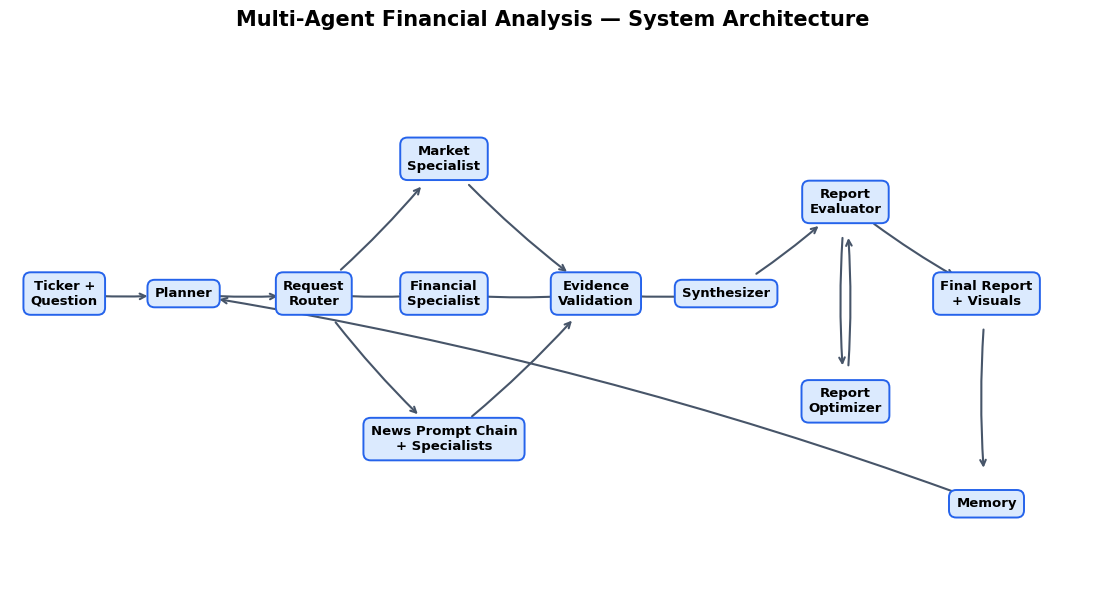

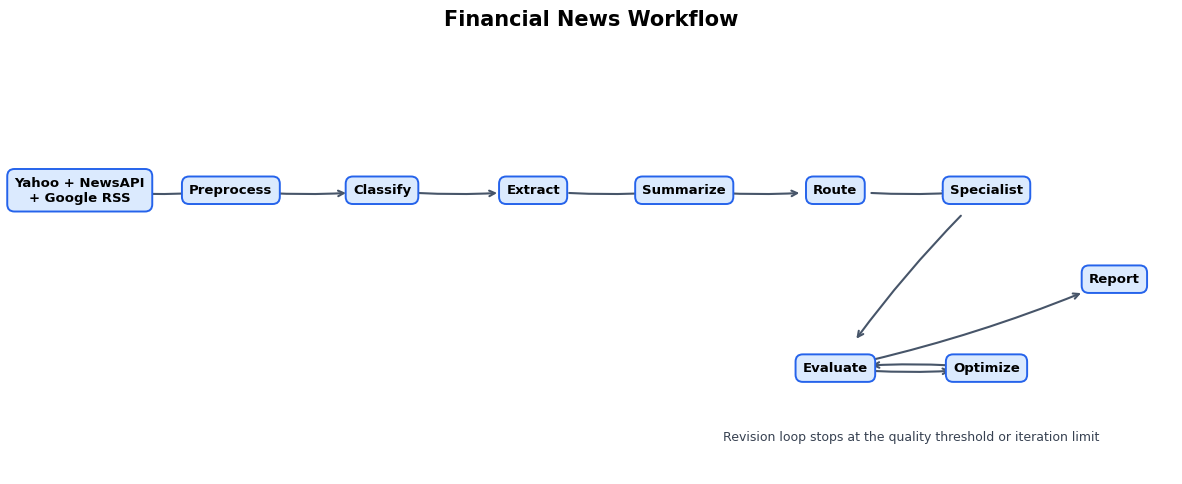

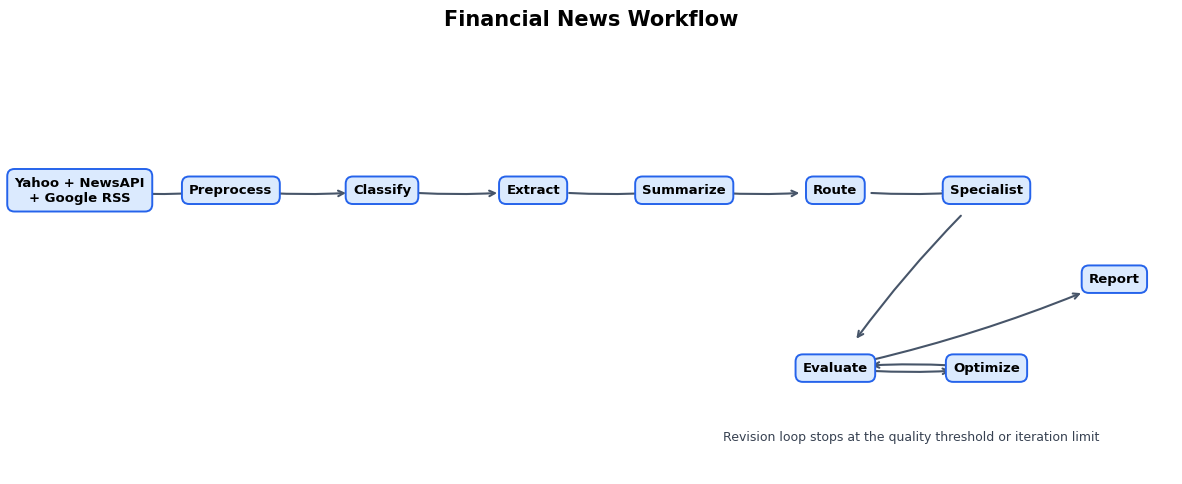

In [4]:
plot_system_architecture()
plot_news_workflow()


## 6. Prompt chaining, routing, and evaluator–optimizer logic

The updated news workflow uses provider isolation and explicit fallback logic:

```mermaid
flowchart LR
    Y[Yahoo Finance] --> D[Deduplicate and newest-sort]
    N[NewsAPI] --> D
    Y --> F{Coverage sparse?}
    N --> F
    F -->|Yes| G[Google News RSS]
    G --> D
    D --> P[Preprocess]
    P --> C[Classify]
    C --> X[Extract facts, figures, events]
    X --> S[Structured summary]
    S --> R{Route by category}
    R --> E[Earnings]
    R --> M[Market]
    R --> W[General news]
    E --> V[4 x 25-point evaluation]
    M --> V
    W --> V
    V -->|Below threshold| O[Optimizer]
    O --> V
    V -->|Pass or max iterations| Z[Synthesis]
```

Provider failures are retained in `source_errors`; original and optimized analyses plus every evaluation score remain in workflow state for auditability. NewsAPI and RSS use retry-enabled HTTP sessions for transient 429/5xx and connection failures.


## 7. End-to-end investment research run

The next cell performs two live LangGraph runs for the same request. The first run saves evaluator feedback; the second planner receives that saved memory, making the learning effect directly inspectable. Each run:

1. accepts and classifies the research request;
2. conditionally routes to market, financial, news, or all specialists;
3. retrieves Yahoo Finance, SEC, and prompt-processed news evidence as selected;
4. validate observations;
5. reflect on evidence quality;
6. synthesize the report;
7. scores the complete report across six criteria;
8. revises and re-evaluates below-threshold reports up to a configured limit; and
9. saves reusable evaluator feedback when memory is enabled.

A running local Ollama model and network access are required for a complete live result. Missing optional providers are recorded rather than treated as fatal.


In [5]:
demo_memory_dir = Path(tempfile.mkdtemp(prefix="aai520-notebook-memory-"))
demo_memory_store = ResearchMemoryStore(demo_memory_dir / "research_memory.json")
workflow = build_research_workflow(
    project_root=PROJECT_ROOT,
    memory_store=demo_memory_store,
)
print("FIRST RUN — establish evidence and save feedback")
first_result = workflow.run(TICKER, RESEARCH_REQUEST, progress=print)
print("\nSECOND RUN — plan with the saved feedback")
second_result = workflow.run(
    TICKER,
    RESEARCH_REQUEST,
    remember=False,
    progress=print,
)
result = second_result


FIRST RUN — establish evidence and save feedback
Planning and routing the research request
Running all selected research specialists
Running market tool: company_info
Running market tool: price_data
Running financial tool: balance_sheet
Running financial tool: cash_flow
Running financial tool: company_info
Running financial tool: financial_growth
Running financial tool: financials
Running financial tool: sec_edgar
Processing news article 1/8
Processing news article 2/8
Processing news article 3/8
Processing news article 4/8
Processing news article 5/8
Processing news article 6/8
Processing news article 7/8
Processing news article 8/8
Validating specialist observations
Reflecting on evidence quality
Synthesizing the draft report
Scoring the complete report
Revising the complete report (iteration 1)
Scoring the complete report
Finalizing the evaluated report
Saving evaluator feedback for a future run

SECOND RUN — plan with the saved feedback
Planning and routing the research request
Run

### 7.1 Structured planning and quality artifacts


In [6]:
review_artifacts = {
    "symbol": result["symbol"],
    "research_request": result.get("research_request"),
    "request_route": result.get("request_route"),
    "selected_specialists": result.get("selected_specialists", []),
    "plan": result.get("plan", {}),
    "specialist_analyses": result.get("specialist_analyses", {}),
    "validation": result.get("validation", []),
    "reflection": result.get("reflection", {}),
    "report_evaluation": result.get("report_evaluation", {}),
    "report_revision_history": result.get("report_revision_history", []),
    "graph_trace": result.get("graph_trace", []),
}
print(json.dumps(review_artifacts, indent=2, default=str))
display(pd.DataFrame([{
    "research_request": result.get("research_request"),
    "selected_route": result.get("request_route"),
    "selected_specialists": ", ".join(result.get("selected_specialists", [])),
}]))


{
  "symbol": "AAPL",
  "research_request": "How do market performance, financial condition, SEC evidence, and recent news affect the company's current risk picture?",
  "request_route": "comprehensive",
  "selected_specialists": [
    "market",
    "financial",
    "news"
  ],
  "plan": {
    "objectives": [
      "Analyze the impact of market performance on AAPL's risk picture",
      "Assess the influence of financial condition on AAPL's risk profile",
      "Evaluate the relevance of SEC evidence on AAPL's risk assessment",
      "Investigate the effect of recent news on AAPL's risk picture"
    ],
    "tools": [
      "balance_sheet",
      "cash_flow",
      "company_info",
      "financial_growth",
      "financials",
      "price_data",
      "sec_edgar"
    ],
    "questions": [
      "What is AAPL's current market capitalization, and how does it compare to its historical levels?",
      "What is AAPL's debt-to-equity ratio, and how does it reflect the company's financial heal

,research_request,selected_route,selected_specialists
0,"How do market performance, financial condition...",comprehensive,"market, financial, news"


### 7.2 Collected market, fundamental, and SEC evidence

The main report shows compact evidence tables so the important values and reporting periods remain reviewable. The complete observation object is retained in the companion audit HTML generated in the appendix. Provider errors appear alongside successful results instead of being hidden.


In [7]:
observations = result.get("observations", {})
market_fields = {
    "price_data": ["latest_price", "1m_return_percent", "3m_return_percent", "1y_return_percent", "annualized_volatility_percent", "maximum_drawdown_percent", "52_week_high", "52_week_low", "latest_volume", "average_volume"],
    "company_info": ["longName", "sector", "industry", "marketCap", "enterpriseValue", "trailingPE", "forwardPE", "dividendYieldPercent"],
}
snapshot_rows = []
for source_name, field_names in market_fields.items():
    payload = observations.get(source_name, {})
    for field_name in field_names:
        if field_name in payload:
            snapshot_rows.append({"source": source_name, "metric": field_name, "value": payload[field_name]})
display(Markdown("#### Market and company snapshot"))
display(pd.DataFrame(snapshot_rows))

statement_rows = []
for source_name in ("financials", "cash_flow"):
    for metric, periods in observations.get(source_name, {}).items():
        if isinstance(periods, dict) and periods:
            period, value = next(iter(periods.items()))
            statement_rows.append({"source": source_name, "metric": metric, "period": period, "value": value})
display(Markdown("#### Latest income-statement and cash-flow observations"))
display(pd.DataFrame(statement_rows))

balance_sheet = observations.get("balance_sheet", {})
balance_period = balance_sheet.get("trends", {}).get("latest_period")
balance_rows = [{"metric": key, "period": balance_period, "value": value} for key, value in balance_sheet.get("latest", {}).items()]
growth_rows = [{"metric": key, "period": f"{observations.get('financial_growth', {}).get('prior_period')} to {observations.get('financial_growth', {}).get('latest_period')}", "value": value} for key, value in observations.get("financial_growth", {}).items() if key.endswith("_percent")]
display(Markdown("#### Balance sheet and deterministic growth"))
display(pd.DataFrame(balance_rows + growth_rows))

sec_evidence = observations.get("sec_edgar", {})
sec_fact_rows = [{"fact": label, **fact} for label, fact in sec_evidence.get("official_company_facts", {}).items()]
display(Markdown("#### SEC company facts and filing periods"))
display(pd.DataFrame(sec_fact_rows))
display(pd.DataFrame(sec_evidence.get("recent_filings", [])))
if sec_evidence.get("error"):
    print(f"SEC EDGAR: {sec_evidence['error']}")
print("Complete raw observations are preserved in the companion audit HTML.")


#### Market and company snapshot

,source,metric,value
0,price_data,latest_price,343.46
1,price_data,1m_return_percent,1.92
2,price_data,3m_return_percent,5.26
3,price_data,1y_return_percent,36.64
4,price_data,annualized_volatility_percent,24.4
5,price_data,maximum_drawdown_percent,-13.8
6,price_data,52_week_high,348.15
7,price_data,52_week_low,242.76
8,price_data,latest_volume,59895300.0
9,price_data,average_volume,48103449.4


#### Latest income-statement and cash-flow observations

,source,metric,period,value
0,financials,Total Revenue,2025-09-30 00:00:00,4.161610e+11
1,financials,Operating Expenses,2025-09-30 00:00:00,6.215100e+10
2,financials,Operating Income,2025-09-30 00:00:00,1.330500e+11
3,financials,Net Income,2025-09-30 00:00:00,1.120100e+11
4,financials,EBITDA,2025-09-30 00:00:00,1.447480e+11
5,financials,Diluted EPS,2025-09-30 00:00:00,7.460000e+00
6,cash_flow,Operating Cash Flow,2025-09-30 00:00:00,1.114820e+11
7,cash_flow,Free Cash Flow,2025-09-30 00:00:00,9.876700e+10
8,cash_flow,Capital Expenditure,2025-09-30 00:00:00,-1.271500e+10


#### Balance sheet and deterministic growth

,metric,period,value
0,cash,2025-09-30 00:00:00,5.469700e+10
1,debt,2025-09-30 00:00:00,9.865700e+10
2,net_debt,2025-09-30 00:00:00,4.396000e+10
3,cash_to_debt_ratio,2025-09-30 00:00:00,5.544000e-01
4,total_assets,2025-09-30 00:00:00,3.592410e+11
5,total_liabilities,2025-09-30 00:00:00,2.855080e+11
6,stockholders_equity,2025-09-30 00:00:00,7.373300e+10
7,revenue_growth_percent,2024-09-30 00:00:00 to 2025-09-30 00:00:00,6.430000e+00
8,net_income_growth_percent,2024-09-30 00:00:00 to 2025-09-30 00:00:00,1.950000e+01
9,diluted_eps_growth_percent,2024-09-30 00:00:00 to 2025-09-30 00:00:00,2.270000e+01


#### SEC company facts and filing periods

,fact,value,unit,fiscal_year,fiscal_period,form,period_end,filed,accession
0,Revenue,3.643570e+11,USD,2026,Q3,10-Q,2026-06-27,2026-07-31,0000320193-26-000020
1,Net Income,1.014640e+11,USD,2026,Q3,10-Q,2026-06-27,2026-07-31,0000320193-26-000020
2,Operating Income,1.224320e+11,USD,2026,Q3,10-Q,2026-06-27,2026-07-31,0000320193-26-000020
3,Operating Expenses,5.635000e+10,USD,2026,Q3,10-Q,2026-06-27,2026-07-31,0000320193-26-000020
4,Operating Cash Flow,1.169960e+11,USD,2026,Q3,10-Q,2026-06-27,2026-07-31,0000320193-26-000020
5,Assets,3.832660e+11,USD,2026,Q3,10-Q,2026-06-27,2026-07-31,0000320193-26-000020
6,Liabilities,2.757460e+11,USD,2026,Q3,10-Q,2026-06-27,2026-07-31,0000320193-26-000020
7,Stockholders Equity,1.075200e+11,USD,2026,Q3,10-Q,2026-06-27,2026-07-31,0000320193-26-000020
8,Diluted EPS,6.880000e+00,USD/shares,2026,Q3,10-Q,2026-06-27,2026-07-31,0000320193-26-000020


,form,filing_date,report_date,accession,filing_url
0,10-Q,2026-07-31,2026-06-27,0000320193-26-000020,https://www.sec.gov/Archives/edgar/data/320193...
1,8-K,2026-07-30,2026-07-30,0000320193-26-000018,https://www.sec.gov/Archives/edgar/data/320193...
2,10-Q,2026-05-01,2026-03-28,0000320193-26-000013,https://www.sec.gov/Archives/edgar/data/320193...
3,8-K,2026-04-30,2026-04-30,0000320193-26-000011,https://www.sec.gov/Archives/edgar/data/320193...
4,8-K,2026-04-20,2026-04-17,0001140361-26-015711,https://www.sec.gov/Archives/edgar/data/320193...
5,8-K,2026-02-24,2026-02-24,0001140361-26-006577,https://www.sec.gov/Archives/edgar/data/320193...
6,10-Q,2026-01-30,2025-12-27,0000320193-26-000006,https://www.sec.gov/Archives/edgar/data/320193...
7,8-K,2026-01-29,2026-01-29,0000320193-26-000005,https://www.sec.gov/Archives/edgar/data/320193...


Complete raw observations are preserved in the companion audit HTML.


### 7.3 Detailed news analysis

This table surfaces source provenance, routing decisions, final evaluator scores, and optimizer activity. The structural score measures field completeness and source traceability; the separate substantive score measures financial reasoning and event significance. A 100 structural score must not be interpreted as perfect financial analysis. Complete per-article records remain in the companion audit HTML.


In [8]:
news_analysis = result.get("news_analysis", {})
news_rows = []
for index, article in enumerate(news_analysis.get("articles", []), start=1):
    evaluation = article.get("evaluation", {})
    news_rows.append({
        "article": index,
        "source": article.get("source"),
        "published_at": article.get("published_at"),
        "headline": article.get("title"),
        "category": article.get("category"),
        "classification_confidence": article.get("classification_confidence"),
        "company": article.get("extracted", {}).get("company"),
        "event": article.get("extracted", {}).get("event"),
        "event_dates": article.get("extracted", {}).get("event_dates"),
        "sentiment": article.get("extracted", {}).get("sentiment"),
        "specialist": article.get("specialist"),
        "structural_score": evaluation.get("score"),
        "structural_passed": evaluation.get("passed"),
        "substantive_reasoning_score": evaluation.get("substantive_reasoning_score"),
        "substantive_reasoning_passed": evaluation.get("substantive_reasoning_passed"),
        "optimizer_revisions": len(article.get("optimization_history", [])),
        "url": article.get("url"),
    })

display(pd.DataFrame(news_rows))
print(json.dumps({
    "pipeline_stages": news_analysis.get("pipeline_stages", []),
    "retrieved_at": news_analysis.get("retrieved_at"),
    "retrieved_counts": news_analysis.get("retrieved_counts", {}),
    "source_errors": news_analysis.get("source_errors", {}),
    "source_counts": news_analysis.get("source_counts", {}),
    "routing_counts": news_analysis.get("routing_counts", {}),
    "average_structural_score": news_analysis.get("average_structural_score", news_analysis.get("average_score")),
    "average_substantive_reasoning_score": news_analysis.get("average_substantive_reasoning_score"),
    "score_scope": news_analysis.get("score_scope"),
    "passed_count": news_analysis.get("passed_count", 0),
}, indent=2, default=str))


,article,source,published_at,headline,category,classification_confidence,company,event,event_dates,sentiment,specialist,structural_score,structural_passed,substantive_reasoning_score,substantive_reasoning_passed,optimizer_revisions,url
0,1,Google News RSS,2026-10-17T14:50:51+00:00,Apple Inc. $AAPL Stock: HWG Holdings LP Raises...,market,0.9,Apple Inc.,Raises Stake,[],mixed,market,100,True,0,False,0,https://news.google.com/rss/articles/CBMirwFBV...
1,2,Google News RSS,2026-10-17T14:50:51+00:00,"3,459 Apple Inc. $AAPL Shares Bought by Titlei...",market,0.9,Apple Inc.,Shares Bought,[2023-12-20],neutral,market,100,True,50,False,0,https://news.google.com/rss/articles/CBMixgFBV...
2,3,Google News RSS,2026-10-17T13:39:16+00:00,Apple Inc. (AAPL) Stock Forecasts - Yahoo! Fin...,market,0.9,Apple Inc.,None,[],mixed,market,100,True,0,False,0,https://news.google.com/rss/articles/CBMikAFBV...
3,4,Google News RSS,2026-10-17T07:37:28+00:00,Apple Inc. $AAPL Stock Sold by Chickasaw Capit...,market,0.8,Apple Inc.,Sold,[No event dates provided],negative,market,100,True,0,False,0,https://news.google.com/rss/articles/CBMivwFBV...
4,5,Google News RSS,2026-10-17T07:37:28+00:00,"30,425 Apple Inc. $AAPL Shares Sold by Everhar...",market,0.8,Apple Inc.,Shares Sold,"[30,425]",neutral,market,100,True,50,False,0,https://news.google.com/rss/articles/CBMiwwFBV...
5,6,Google News RSS,2026-10-17T07:28:28+00:00,Apple Inc. (AAPL) Price: Live Chart & Market C...,market,0.9,Apple Inc.,None,[],neutral,market,100,True,50,False,0,https://news.google.com/rss/articles/CBMiT0FVX...
6,7,Google News RSS,2026-10-17T06:33:25+00:00,Apple Inc. (AAPL) - What Are Researchers Sayin...,market,0.9,Apple Inc.,None,[],neutral,market,100,True,0,False,0,https://news.google.com/rss/articles/CBMiwAFBV...
7,8,Google News RSS,2026-10-13T12:00:02+00:00,Apple Inc. (AAPL) is Attracting Investor Atten...,market,0.9,Apple Inc.,Attracting Investor Attention,[],mixed,market,100,True,50,False,0,https://news.google.com/rss/articles/CBMioAFBV...


{
  "pipeline_stages": [
    "ingest",
    "preprocess",
    "classify",
    "extract",
    "summarize",
    "route",
    "specialist",
    "evaluate",
    "optimize"
  ],
  "retrieved_at": "2026-10-18T01:44:55.436751+00:00",
  "retrieved_counts": {
    "Yahoo Finance": 0,
    "NewsAPI": 0,
    "Google News RSS": 8
  },
  "source_errors": {},
  "source_counts": {
    "Google News RSS": 8
  },
  "routing_counts": {
    "market": 8
  },
  "average_structural_score": 100.0,
  "average_substantive_reasoning_score": 25.0,
  "score_scope": "Structural completeness and source traceability are scored separately from substantive financial reasoning and event significance.",
  "passed_count": 8
}


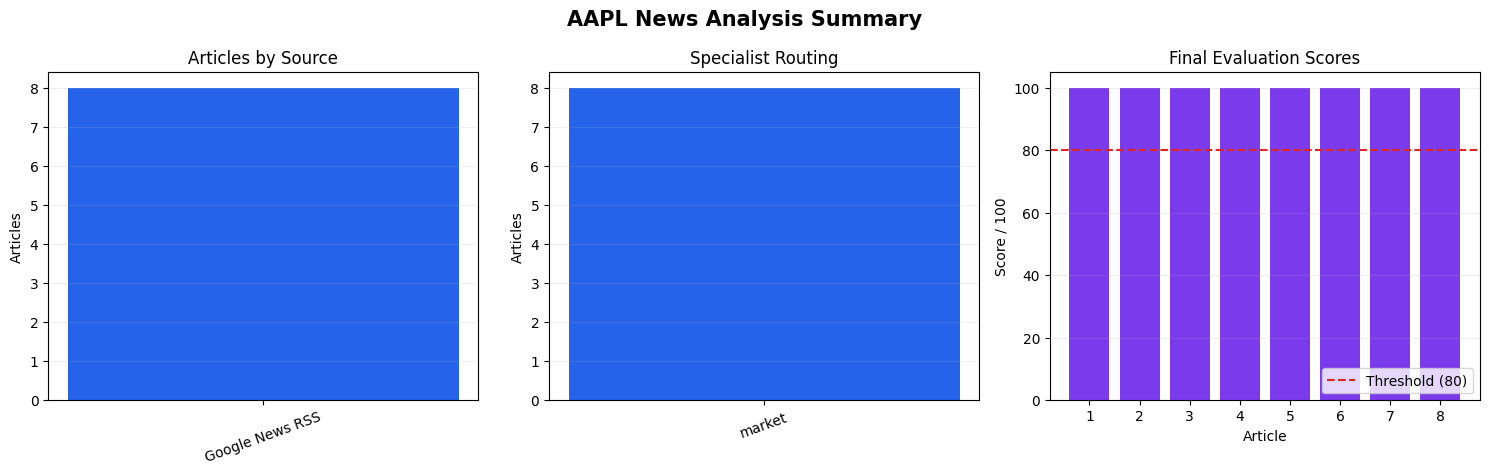

In [9]:
news_figure = plot_news_analysis_summary(news_analysis)
if news_figure is None:
    display(Markdown("*No news-summary chart is available because no articles were retrieved.*"))


## 8. Final research report

The model-generated report uses only collected observations and explicitly distinguishes evidence, interpretation, risk, uncertainty, and missing data.


In [10]:
display(Markdown(result["report"]))


**Apple Inc. (AAPL) Current Risk Picture Analysis**
==============================================

### Company Overview

* Company Name: Apple Inc.
* Symbol: AAPL
* Sector: Technology
* Industry: Consumer Electronics
* Country: United States

### Market Performance

#### Valuation and Profitability

* Trailing PE: 39.388x

#### Financial Performance


#### Cash Flow


#### SEC EDGAR Evidence

* Entity Name: Apple Inc.
* CIK: 0000320193
* SIC Classification: 3571
* Every Supplied Official Company Fact:
	+ Cash/Debt Ratio (2025-09-30 00:00:00): 0.5544

#### Dividend


#### Recent News and Catalysts

* News Source: MarketBeat
* Publisher: Google News RSS
* Publication Date: 2026-10-17T07:28:28+00:00
* Headline: Apple Inc. (AAPL) Price: Live Chart & Market Cap - CryptoRank
* Detected Events: None
* Routed Specialist: market
* Structural Completeness/Traceability Score: 100
* Feedback: Structural completeness passed, but substantive financial reasoning or event-significance analysis remains limited.
* Optimized Observations: None
* Interpretation: The supplied article provides evidence relevant to share price, market activity, analyst commentary, and valuation.
* Uncertainties: The provider payload may contain only a headline or snippet; verify the linked source.

### Risks and Uncertainties

* None identified.

### Data Quality

* Verified values: All financial metrics and all company facts are verified against multiple sources.
* Suspicious values: None identified.
* Missing information: None identified.
* Follow-up questions: Verify the linked source and corroborate with primary financial data.

### Further Research

* Future research should prioritize substantive financial reasoning and event-significance analysis, as well as ensuring data quality by verifying values across multiple sources.

### Verification Scope

SEC facts provide primary-source evidence for selected financial metrics. Market data and news remain provider-supplied and require independent verification.

### Verified Financial Metrics

The following values are rendered deterministically from provider observations; no model arithmetic is used.

## Verified Financial Metrics

The following values are rendered deterministically from provider observations; no model arithmetic is used.

- **Current Price**: $343.46
- **Market Capitalization**: $5,012,516,765,696
- **Enterprise Value**: $5,034,461,888,512
- **Start Price**: $251.36
- **Latest Price**: $343.46
- **One-Month Return**: 1.92%
- **Three-Month Return**: 5.26%
- **One-Year Return**: 36.64%
- **Annualized Volatility**: 24.40%
- **Maximum Drawdown**: -13.80%
- **52-Week High**: $348.15
- **52-Week Low**: $242.76
- **Latest Volume**: 59,895,300
- **Average Volume**: 48,103,449
- **Price Observation Count**: 251
- **Trailing P/E**: 39.388x
- **Forward P/E**: 35.860x
- **Price/Sales**: 10.738x
- **Profit Margin**: 27.62%
- **Operating Margin**: 32.62%
- **Return on Equity**: 148.75%
- **Beta**: 1.069x
- **Revenue** (2025-09-30 00:00:00): $416,161,000,000
- **Operating Expenses** (2025-09-30 00:00:00): $62,151,000,000
- **Operating Income** (2025-09-30 00:00:00): $133,050,000,000
- **Net Income** (2025-09-30 00:00:00): $112,010,000,000
- **EBITDA** (2025-09-30 00:00:00): $144,748,000,000
- **Diluted EPS** (2025-09-30 00:00:00): $7.46
- **Operating Cash Flow** (2025-09-30 00:00:00): $111,482,000,000
- **Free Cash Flow** (2025-09-30 00:00:00): $98,767,000,000
- **Capital Expenditure** (2025-09-30 00:00:00): -$12,715,000,000
- **EBITDA / Net Income** (2025-09-30 00:00:00): 1.292x
- **Dividend Yield**: 0.31% (Yahoo Finance supplies this field in percentage points.)
- **Cash and Short-Term Investments** (2025-09-30): $54,697,000,000
- **Total Debt** (2025-09-30): $98,657,000,000
- **Net Debt** (2025-09-30): $43,960,000,000
- **Total Assets** (2025-09-30): $359,241,000,000
- **Total Liabilities** (2025-09-30): $285,508,000,000
- **Stockholders' Equity** (2025-09-30): $73,733,000,000
- **Cash / Debt** (2025-09-30): 0.554x
- **Revenue Growth** (2024-09-30 to 2025-09-30): 6.43%
- **Net Income Growth** (2024-09-30 to 2025-09-30): 19.50%
- **Diluted EPS Growth** (2024-09-30 to 2025-09-30): 22.70%
- **Cash Trend** (2024-09-30 to 2025-09-30): -16.07%
- **Debt Trend** (2024-09-30 to 2025-09-30): -7.48%
- **Assets Trend** (2024-09-30 to 2025-09-30): -1.57%
- **Liabilities Trend** (2024-09-30 to 2025-09-30): -7.31%
- **Equity Trend** (2024-09-30 to 2025-09-30): 29.47%

## Evidence-Based Interpretation

Because the one-year return was 36.64% while annualized volatility was 24.40% and maximum drawdown was -13.80%, the historical return must be considered together with measured price risk; these observations do not predict future performance.

Revenue growth of 6.43% and net-income growth of 19.50% indicate the latest year-over-year statement changes. Cash of $54,697,000,000 compared with total debt of $98,657,000,000 shows the reported balance-sheet exposure; however, these period snapshots alone do not establish future liquidity or earnings durability.

SEC EDGAR supplied 9 official company fact(s) and 8 recent filing record(s), providing primary-source corroboration; however, filing periods and provider statement periods should be compared explicitly before drawing conclusions.

Yahoo Finance reports stockholders' equity of $73,733,000,000 for 2025-09-30, while SEC company facts report $107,520,000,000 for fiscal 2026 Q3 ended 2026-06-27. These values describe different reporting periods and provider snapshots and should not be treated as the same balance-sheet date.

The news workflow processed 8 article(s). The structural completeness and source-traceability rubric averaged 100.00%. The separate substantive financial-reasoning and event-significance score averaged 25.00%. A 100% structural score means the expected fields and traceable source evidence were present; it does not establish perfect financial analysis. Because provider payloads may contain only headlines or snippets, detected events remain uncertain and should be verified at the linked publishers.

Taken together, the market measurements, financial condition, SEC evidence, and current news indicate a mixed, evidence-bounded risk picture rather than a forecast or an investment recommendation.

### 8.1 Deterministic report view

This second rendering guarantees that the core company overview, price performance, valuation, financial performance, cash flow, dividend, SEC filing evidence, news-source coverage, validation findings, and missing information remain visible even if model prose varies between runs.


In [11]:
print(render_console_summary(result, include_article_details=False))


FINAL RESEARCH REPORT

Apple Inc. (AAPL)
----------------------------------------------------------------------

1. COMPANY OVERVIEW
   Sector:              Technology
   Industry:            Consumer Electronics
   Country:             United States
   Current Price:       $343.46
   Market Cap:          $5.013T
   Enterprise Value:    $5.034T

2. PRICE PERFORMANCE
   Start Price:         $251.36
   Latest Price:        $343.46
   One-Year Return:     36.64%
   Annualized Volatility: 24.40%
   Maximum Drawdown:    -13.80%
   Observations:        251

3. VALUATION
   Trailing P/E:        39.39
   Forward P/E:         35.86
   Price/Sales (TTM):   10.74
   Profit Margin:       27.62%
   Operating Margin:    32.62%
   Return on Equity:    148.75%
   Beta:                1.069

4. FINANCIAL PERFORMANCE (2025)
   Revenue:             $416.161B
   Operating Expenses:  $62.151B
   Operating Income:    $133.050B
   Net Income:          $112.010B
   EBITDA:              $144.748B
   Diluted EP

## 9. Ten-year market context

The original notebook's 10-year graph is preserved as a reusable reporting function. It uses adjusted closing prices and reports the start price, end price, and total return.


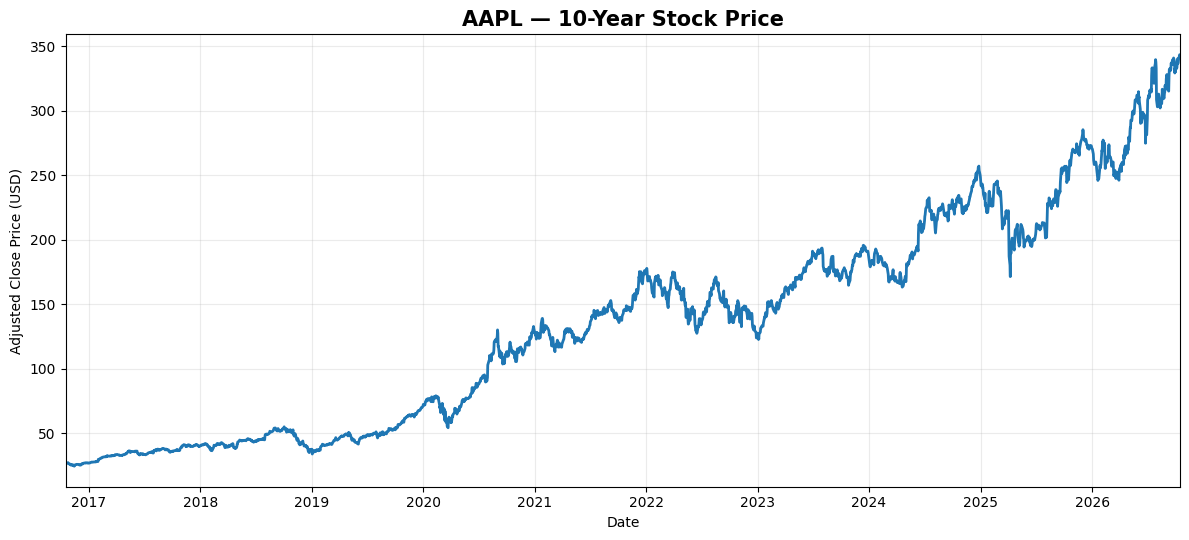

10-year price summary: $26.88 → $343.46 (+1,177.7%)


In [12]:
try:
    price_chart = plot_10_year_stock_price(YahooFinanceClient(), TICKER)
    if price_chart is None:
        display(Markdown(f"*No 10-year price history was available for {TICKER}.*"))
    else:
        print(price_chart.summary)
except Exception as exc:
    display(Markdown(f"*The 10-year chart could not be loaded: {type(exc).__name__}: {exc}*"))


## 10. Revenue and operating-expense context

The financial tool retains directly reported operating expenses when available and fills only missing periods with `Gross Profit − Operating Income`. Generic total-cost rows are deliberately excluded because they may include cost of revenue. The first chart compares revenue with operating expenses across up to five available annual periods; the second isolates the operating-expense trend.


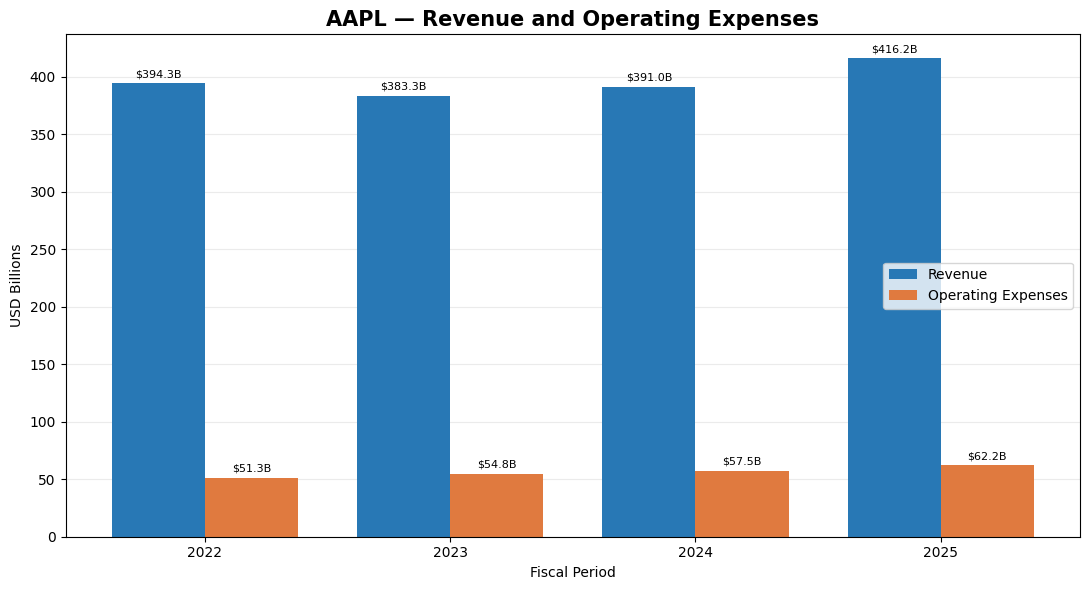

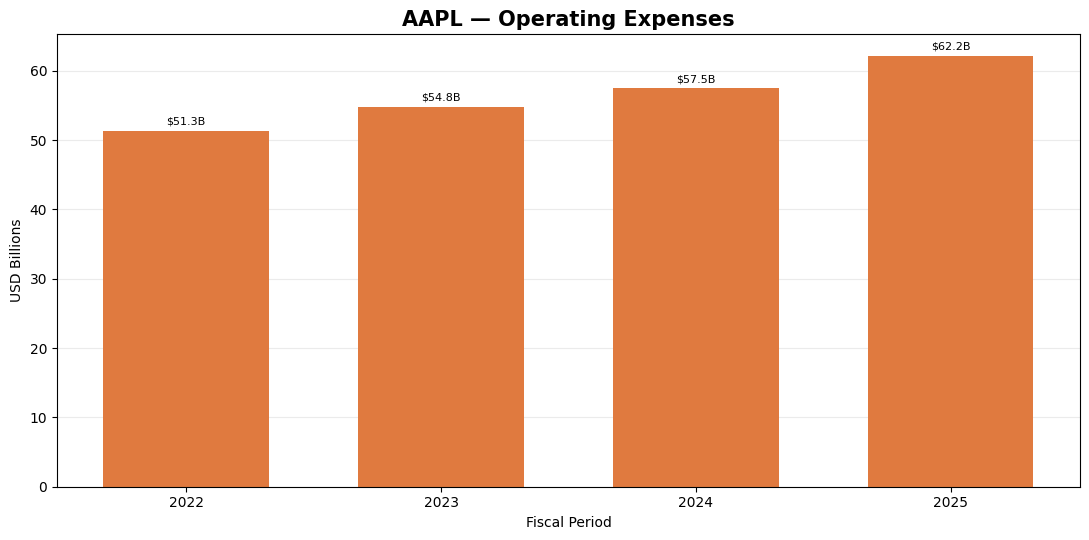

In [13]:
financial_observations = result.get("observations", {}).get("financials", {})
revenue_expense_figure = plot_revenue_and_operating_expenses(
    financial_observations,
    TICKER,
)
if revenue_expense_figure is None:
    display(Markdown("*Revenue data was unavailable for the comparison chart.*"))

expense_figure = plot_operating_expenses(financial_observations, TICKER)
if expense_figure is None:
    display(Markdown("*Operating-expense data was unavailable for the standalone chart.*"))


## 11. Evaluation evidence and iteration

Each news analysis receives a **structural completeness and source-traceability score** with 25 points for each of the following:

- at least one concrete observation;
- a clear interpretation;
- an explicit uncertainty or missing-information statement; and
- at least two evidence-based observations.

A separate substantive score checks whether the observations go beyond headline/source metadata and whether the interpretation explains financial reasoning or event significance. Thus, 100/100 on the structural rubric establishes expected fields and traceability—not perfect financial analysis. Below-threshold structural work is revised up to `MAX_OPTIMIZER_ITERATIONS`. The complete report is separately scored for completeness, grounding, reasoning, consistency, sources, and clarity; LangGraph routes a failed draft through the report optimizer and back to evaluation up to `MAX_REPORT_REVISIONS`. Before/after scores and every graph node are retained below.


In [14]:
report_iteration_rows = [
    {
        "evaluation": index,
        "score": evaluation.get("score"),
        "passed": evaluation.get("passed"),
        **evaluation.get("criteria", {}),
    }
    for index, evaluation in enumerate(result.get("report_evaluation_history", []))
]
display(Markdown("### Complete-report evaluator–optimizer history"))
display(pd.DataFrame(report_iteration_rows))
print(json.dumps({
    "report_revisions": result.get("report_revision_history", []),
    "graph_trace": result.get("graph_trace", []),
}, indent=2, default=str))

iteration_rows = []
for index, article in enumerate(news_analysis.get("articles", []), start=1):
    for revision, evaluation in enumerate(article.get("evaluation_history", [])):
        iteration_rows.append({
            "article": index,
            "revision": revision,
            "structural_score": evaluation.get("score"),
            "structural_passed": evaluation.get("passed"),
            "substantive_reasoning_score": evaluation.get("substantive_reasoning_score"),
            "feedback": "; ".join(evaluation.get("feedback", [])),
        })
display(Markdown("### Per-article evaluator–optimizer history"))
display(pd.DataFrame(iteration_rows))

request_router = ResearchRequestRouter()
routing_examples = [
    ("market-only routing", "Analyze price, volatility, and volume", "market"),
    ("financial-only routing", "Review revenue, debt, and the balance sheet", "financial"),
    ("news-only routing", "Summarize recent news sentiment and catalysts", "news"),
    ("comprehensive routing", "Compare market returns with earnings and recent news", "comprehensive"),
]
behavior_rows = []
for requirement, request_text, expected_route in routing_examples:
    route_result = request_router.route(request_text, TOOLS.keys(), has_news_pipeline=True)
    behavior_rows.append({"requirement": requirement, "expected": expected_route, "actual": route_result["route"], "passed": route_result["route"] == expected_route})

report_evaluator = EvaluatorAgent(lambda _prompt: "{}")
weak_report_result = report_evaluator.evaluate_report("# Note\n\nLooks fine.", result.get("observations", {}), RESEARCH_REQUEST, result.get("request_route", "comprehensive"))
strong_report_result = result.get("report_evaluation", {})
behavior_rows.extend([
    {"requirement": "weak complete-report test", "expected": "fail", "actual": "pass" if weak_report_result.get("passed") else "fail", "passed": not weak_report_result.get("passed", False)},
    {"requirement": "strong complete-report test", "expected": "pass", "actual": "pass" if strong_report_result.get("passed") else "fail", "passed": bool(strong_report_result.get("passed"))},
])
learned_question = "Which material claims can be linked to filing-level citations or provider source URLs?"
first_questions = first_result.get("plan", {}).get("questions", [])
second_questions = second_result.get("plan", {}).get("questions", [])
memory_behavior_passed = bool(second_result.get("plan", {}).get("memory_context")) and learned_question not in first_questions and learned_question in second_questions
behavior_rows.append({"requirement": "two-run memory test", "expected": "Run 2 retrieves feedback and adds a filing/source traceability question", "actual": f"memory_retrieved={bool(second_result.get('plan', {}).get('memory_context'))}; traceability_question_added={learned_question not in first_questions and learned_question in second_questions}", "passed": memory_behavior_passed})
display(Markdown("### Requirement-specific behavioral demonstration"))
display(pd.DataFrame(behavior_rows))

test_run = subprocess.run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=False,
)
display(Markdown("### Behavioral and regression test results"))
print(test_run.stdout.strip())
if test_run.returncode:
    print(test_run.stderr.strip())
print(f"pytest exit code: {test_run.returncode}")


### Complete-report evaluator–optimizer history

,evaluation,score,passed,completeness,grounding,reasoning,consistency,sources,clarity
0,0,82.5,False,100.0,100.0,15.0,100.0,80.0,100.0
1,1,90.0,True,100.0,100.0,60.0,100.0,80.0,100.0


{
  "report_revisions": [
    {
      "iteration": 1,
      "before_score": 82.5,
      "after_score": 90.0,
      "feedback": [
        "Improve reasoning; current score is 15/100.",
        "No report can pass while these criteria are below 60/100: reasoning."
      ]
    }
  ],
  "graph_trace": [
    "plan_request",
    "comprehensive_research",
    "validate_observations",
    "reflect",
    "synthesize",
    "evaluate_report",
    "revise_report",
    "evaluate_report",
    "finalize"
  ]
}


### Per-article evaluator–optimizer history

,article,revision,structural_score,structural_passed,substantive_reasoning_score,feedback
0,1,0,100,True,0,"Structural completeness passed, but substantiv..."
1,2,0,100,True,50,"Structural completeness passed, but substantiv..."
2,3,0,100,True,0,"Structural completeness passed, but substantiv..."
3,4,0,100,True,0,"Structural completeness passed, but substantiv..."
4,5,0,100,True,50,"Structural completeness passed, but substantiv..."
5,6,0,100,True,50,"Structural completeness passed, but substantiv..."
6,7,0,100,True,0,"Structural completeness passed, but substantiv..."
7,8,0,100,True,50,"Structural completeness passed, but substantiv..."


### Requirement-specific behavioral demonstration

,requirement,expected,actual,passed
0,market-only routing,market,market,True
1,financial-only routing,financial,financial,True
2,news-only routing,news,news,True
3,comprehensive routing,comprehensive,comprehensive,True
4,weak complete-report test,fail,fail,True
5,strong complete-report test,pass,pass,True
6,two-run memory test,Run 2 retrieves feedback and adds a filing/sou...,memory_retrieved=True; traceability_question_a...,False


### Behavioral and regression test results

................................................................... [ 63%]
..........s............................        [100%]
=============================== warnings summary ===============================
../../../../.local/share/virtualenvs/brandonwirgau-gZAqjFTS/lib/python3.13/site-packages/langgraph/cache/base/__init__.py:8
  /Users/brandonwirgau/.local/share/virtualenvs/brandonwirgau-gZAqjFTS/lib/python3.13/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
    from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
105 passed, 1 skipped, 1 warning, 31 subtests passed in 3.94s
pytest exit code: 0


## 12. Memory and learning across runs

The first run stores concise lessons and evaluator feedback in an isolated demonstration memory file; the second run receives up to the last three ticker-relevant entries in its planner prompt. The comparison below separates successful retrieval from substantive planning improvement. Source-traceability feedback causes the planner to add a filing/source-citation question deterministically; if that trigger is absent, the notebook reports retrieval without claiming learning.


In [15]:
first_plan = first_result.get("plan", {})
second_plan = second_result.get("plan", {})
memory_context = second_plan.get("memory_context", [])
first_questions = first_plan.get("questions", [])
second_questions = second_plan.get("questions", [])
added_questions = [question for question in second_questions if question not in first_questions]
learned_question = "Which material claims can be linked to filing-level citations or provider source URLs?"
source_feedback_text = json.dumps(memory_context, default=str).lower().replace("-", " ")
source_feedback_retrieved = any(marker in source_feedback_text for marker in ("source traceability", "primary source", "filing citation", "source link", "linked source", "citation"))
traceability_question_added = learned_question in added_questions
substantive_plan_improvement = source_feedback_retrieved and traceability_question_added
memory_rows = [
    {"evidence": "Saved feedback records received by Run 2", "run_1": 0, "run_2": len(memory_context), "changed": bool(memory_context)},
    {"evidence": "Selected tools", "run_1": ", ".join(first_plan.get("tools", [])), "run_2": ", ".join(second_plan.get("tools", [])), "changed": first_plan.get("tools") != second_plan.get("tools")},
    {"evidence": "Added planning questions", "run_1": "—", "run_2": "; ".join(added_questions) or "None", "changed": bool(added_questions)},
    {"evidence": "Filing/source traceability question", "run_1": learned_question in first_questions, "run_2": learned_question in second_questions, "changed": traceability_question_added},
]
display(pd.DataFrame(memory_rows))
print("Saved Run 1 feedback:")
print(json.dumps(first_result.get("memory_entry", {}), indent=2, default=str))
if substantive_plan_improvement:
    print("Learning interpretation: Run 1 feedback identified weak source traceability. Run 2 retrieved that feedback and added a question requiring filing-level citations or provider source links. The selected tools did not change because the comprehensive route already included the necessary SEC and provider tools.")
else:
    print("Learning interpretation: successful memory retrieval with no demonstrated substantive planning improvement. Any wording difference alone is not treated as learning.")


,evidence,run_1,run_2,changed
0,Saved feedback records received by Run 2,0,1,True
1,Selected tools,"balance_sheet, cash_flow, company_info, financ...","balance_sheet, cash_flow, company_info, financ...",False
2,Added planning questions,—,"What is AAPL's current market capitalization, ...",True
3,Filing/source traceability question,False,False,False


Saved Run 1 feedback:
{
  "date": "2026-10-18T01:44:27.052609+00:00",
  "symbol": "AAPL",
  "summary": "Here is a summary of reusable research lessons from this AAPL run in 120 words or less, focusing on evidence coverage, data-quality problems, and improvements for a future run:\n\nEvidence coverage: The report provides a wealth of market data, SEC evidence, and news, but lacks substantive financial reasoning and event-significance analysis. Data-quality problems: Some values, such as stockholders' equity, differ between the SEC and Yahoo Finance reports. Follow-up questions and improvements: Corroborate with primary financial data, add concrete observations from articles, and identify uncertainty or missing information. To improve, prioritize substantive financial reasoning and event-significance analysis, and ensure data quality by verifying values across multiple sources.",
  "weaknesses": [
    "Lacks substantive financial reasoning or event-significance analysis"
  ]
}
Learning i

## 13. Limitations, responsible use, and conclusion

- Yahoo Finance, NewsAPI, Google News RSS, and SEC EDGAR can be delayed, unavailable, rate-limited, incomplete, or inconsistent.
- News summaries may contain only provider snippets; source links should be reviewed before decisions.
- Keyword extraction and routing are intentionally transparent but cannot capture every nuance.
- Local-model output is nondeterministic and may still omit context; deterministic validation reduces but cannot eliminate that risk.
- Google News RSS is a coverage fallback, not a replacement for primary or official evidence.
- FRED and Alpha Vantage remain scaffolds and are not represented as report evidence.
- Historical performance, evaluator scores, and model interpretations do not predict future returns.

The final system preserves the original financial-research workflow while incorporating the updated notebook's operating-expense analysis, financial trend charts, and resilient multi-source news retrieval. Its modular adapters, explicit state, provenance, bounded revision loop, deterministic report, persistent memory, offline tests, and generated diagrams make the work reproducible and auditable.


## Appendix — companion audit artifact

The complete workflow state is written to a companion HTML file rather than repeated in the main report. This preserves every plan, observation, article, evaluator result, revision, graph node, and memory artifact while keeping the review copy compact.


In [16]:
audit_path = PROJECT_ROOT / "notebooks" / "multi_agent_financial_analysis_audit.html"
audit_json = json.dumps(result, indent=2, default=str)
audit_document = f"""<!doctype html>
<html lang="en"><head><meta charset="utf-8"><title>Multi-Agent Financial Analysis Audit</title>
<style>body{{font-family:system-ui,sans-serif;max-width:1200px;margin:2rem auto;padding:0 1rem}}pre{{white-space:pre-wrap;overflow-wrap:anywhere;background:#f6f8fa;padding:1rem;border-radius:6px}}</style>
</head><body><h1>Multi-Agent Financial Analysis — Complete Audit State</h1>
<p>Ticker: {html.escape(str(result.get('symbol', '')))}. Generated by the executable notebook; values are preserved without truncation.</p>
<pre>{html.escape(audit_json)}</pre></body></html>"""
audit_path.write_text(audit_document, encoding="utf-8")
audit_summary = [{"artifact": key, "record_count": len(value) if isinstance(value, (list, dict)) else 1} for key, value in result.items()]
display(pd.DataFrame(audit_summary))
print(f"Complete audit artifact: {audit_path}")
print(f"Audit size: {audit_path.stat().st_size:,} bytes")


,artifact,record_count
0,symbol,1
1,research_request,1
2,remember,1
3,request_route,1
4,selected_specialists,3
5,plan,7
6,observations,8
7,specialist_analyses,3
8,news_analysis,16
9,validation,0


Complete audit artifact: /Users/brandonwirgau/Projects/AAI/520/Final Project/notebooks/multi_agent_financial_analysis_audit.html
Audit size: 159,992 bytes
